In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [4]:
np.random.seed(23)
torch.manual_seed(23)

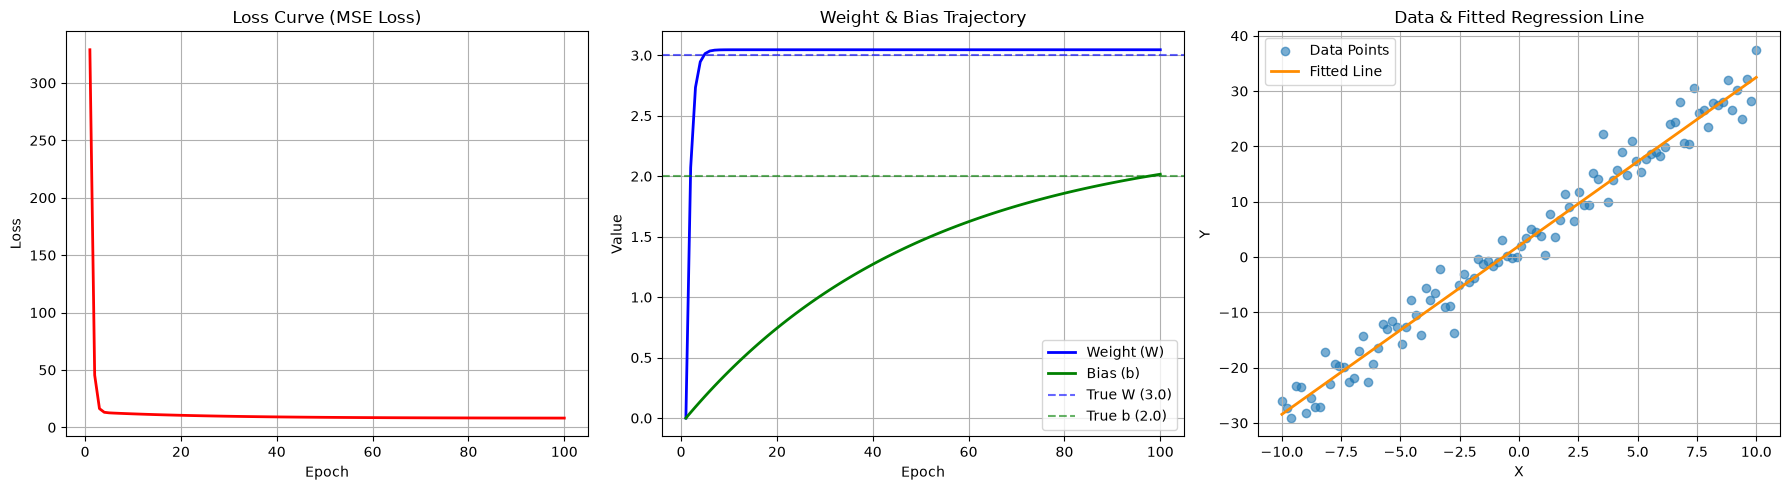

In [5]:
# create random dataset

x_data = np.linspace(-10, 10, 100).reshape(-1, 1)
noise = np.random.randn(100, 1) * 3
y_data = 3.0 * x_data + 2.0 + noise

X = torch.tensor(x_data, dtype = torch.float32)
Y = torch.tensor(y_data, dtype = torch.float32)

model = nn.Linear(1,1)

nn.init.constant_(model.weight, 0.0)
nn.init.constant_(model.bias, 0.0)

# setting Loss Function
criterion = nn.MSELoss()

# setting optimizer
optimizer = optim.SGD(model.parameters(), lr = 0.01)

# model learning / record Loss, Weight
epochs = 100
history = []

for epoch in range(epochs):
    predictions = model(X)
    loss = criterion(predictions, Y)

    current_w = model.weight.item()
    current_b = model.bias.item()
    current_loss = loss.item()

    history.append({
        'epoch' : epoch + 1,
        'loss' : current_loss,
        'weight' : current_w,
        'bias' : current_b,
    })

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

df_history = pd.DataFrame(history)

# Visualization

fig, axes = plt.subplots(1, 3, figsize = (18, 5))

# 그래프 1: 에폭에 따른 오차(Loss) 변화
axes[0].plot(df_history['epoch'], df_history['loss'], color='red', linewidth=2)
axes[0].set_title('Loss Curve (MSE Loss)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

# 그래프 2: 에폭에 따른 가중치(Weight & Bias) 변화
axes[1].plot(df_history['epoch'], df_history['weight'], label='Weight (W)', color='blue', linewidth=2)
axes[1].plot(df_history['epoch'], df_history['bias'], label='Bias (b)', color='green', linewidth=2)
axes[1].axhline(y=3.0, color='blue', linestyle='--', alpha=0.6, label='True W (3.0)')
axes[1].axhline(y=2.0, color='green', linestyle='--', alpha=0.6, label='True b (2.0)')
axes[1].set_title('Weight & Bias Trajectory')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Value')
axes[1].legend()
axes[1].grid(True)

# 그래프 3: 실제 데이터와 최종 회귀선
axes[2].scatter(x_data, y_data, alpha=0.6, label='Data Points')
final_pred = model(X).detach().numpy()
axes[2].plot(x_data, final_pred, color='darkorange', linewidth=2, label='Fitted Line')
axes[2].set_title('Data & Fitted Regression Line')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

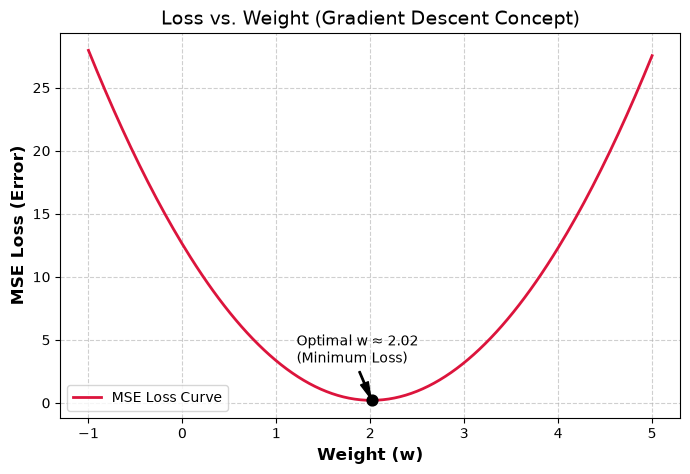

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 가상 데이터 생성 (정답 함수: y = 2x)
np.random.seed(42)
X = np.linspace(-3, 3, 100)
y_true = 2 * X + np.random.normal(0, 0.5, size=100)

# 2. 가중치(w) 범위 설정 (X축)
w_range = np.linspace(-1, 5, 200)
mse_losses = []

# 3. 각 가중치 w에 따른 MSE Loss 계산 (Y축)
for w in w_range:
    y_pred = w * X
    loss = np.mean((y_true - y_pred) ** 2)
    mse_losses.append(loss)

# 4. 그래프 시각화
plt.figure(figsize=(8, 5))
plt.plot(w_range, mse_losses, label='MSE Loss Curve', color='crimson', linewidth=2)

# 최적 가중치(최솟점) 표시
min_idx = np.argmin(mse_losses)
best_w = w_range[min_idx]
min_loss = mse_losses[min_idx]

plt.scatter([best_w], [min_loss], color='black', zorder=5, s=60)
plt.annotate(f'Optimal w ≈ {best_w:.2f}\n(Minimum Loss)', 
             xy=(best_w, min_loss), 
             xytext=(best_w - 0.8, min_loss + 3),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# 축 라벨 및 디자인 설정
plt.xlabel('Weight (w)', fontsize=12, fontweight='bold')
plt.ylabel('MSE Loss (Error)', fontsize=12, fontweight='bold')
plt.title('Loss vs. Weight (Gradient Descent Concept)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Reference : ChatGPT
---

### Actual Data 
$ Y = 3x + 2 $

### Hypothesis 
$ \hat{Y} = wx + b $

### Loss Function 

MSE($w, b$) = $ \frac{1}{N} \sum^{n}_{i = 1} (\hat{y} - y)^2 $

### Update Params 

$ w = w - \alpha \frac{\partial L}{\partial w} $ 

$ b = b - \alpha \frac{\partial L}{\partial b} $

- $\alpha : \text{Learning Rate}$
- $ \text{L : Loss} $



In [9]:
import numpy as np

np.random.seed(8)

x = np.linspace(0, 10, 1000).reshape(-1, 1)
# np.linspace(start, end, num_of_value)
noise = np.random.normal(loc = 0, scale = 3, size = x.shape)
# np.random.normal(loc = mean, scale = std, size = num_of_value)
y = 3 * x + 10 + noise

#weight
w = 0.0
#bias
b = 0.0

learning_rate = 0.01
epochs = 1000

for epoch in range(epochs + 1):
    y_hat = w * x + b
    cost = np.mean((y_hat - y) ** 2)
    dw = np.mean((y_hat - y) * x)
    db = np.mean(y_hat - y)

    w = w - dw * learning_rate
    b = b - db * learning_rate

    if(epoch % 50) == 0:
        print(f"epoch : {epoch}, weight : {w:.3f}, bias : {b:.3f}, cost : {cost:.3f}")

epoch : 0, weight : 1.508, bias : 0.251, cost : 716.008
epoch : 50, weight : 4.264, bias : 1.769, cost : 26.553
epoch : 100, weight : 4.120, bias : 2.722, cost : 22.822
epoch : 150, weight : 3.993, bias : 3.564, cost : 19.902
epoch : 200, weight : 3.880, bias : 4.310, cost : 17.617
epoch : 250, weight : 3.781, bias : 4.969, cost : 15.829
epoch : 300, weight : 3.693, bias : 5.553, cost : 14.429
epoch : 350, weight : 3.615, bias : 6.069, cost : 13.334
epoch : 400, weight : 3.546, bias : 6.526, cost : 12.476
epoch : 450, weight : 3.485, bias : 6.929, cost : 11.806
epoch : 500, weight : 3.431, bias : 7.287, cost : 11.281
epoch : 550, weight : 3.383, bias : 7.603, cost : 10.870
epoch : 600, weight : 3.341, bias : 7.883, cost : 10.548
epoch : 650, weight : 3.304, bias : 8.130, cost : 10.296
epoch : 700, weight : 3.270, bias : 8.349, cost : 10.100
epoch : 750, weight : 3.241, bias : 8.542, cost : 9.945
epoch : 800, weight : 3.215, bias : 8.714, cost : 9.825
epoch : 850, weight : 3.192, bias :

epoch : 0, weight : 1.508, bias : 0.251, cost : 716.008
epoch : 50, weight : 4.264, bias : 1.769, cost : 26.553
epoch : 100, weight : 4.120, bias : 2.722, cost : 22.822
epoch : 150, weight : 3.993, bias : 3.564, cost : 19.902
epoch : 200, weight : 3.880, bias : 4.310, cost : 17.617
epoch : 250, weight : 3.781, bias : 4.969, cost : 15.829
epoch : 300, weight : 3.693, bias : 5.553, cost : 14.429
epoch : 350, weight : 3.615, bias : 6.069, cost : 13.334
epoch : 400, weight : 3.546, bias : 6.526, cost : 12.476
epoch : 450, weight : 3.485, bias : 6.929, cost : 11.806
epoch : 500, weight : 3.431, bias : 7.287, cost : 11.281
epoch : 550, weight : 3.383, bias : 7.603, cost : 10.870
epoch : 600, weight : 3.341, bias : 7.883, cost : 10.548
epoch : 650, weight : 3.304, bias : 8.130, cost : 10.296
epoch : 700, weight : 3.270, bias : 8.349, cost : 10.100
epoch : 750, weight : 3.241, bias : 8.542, cost : 9.945
epoch : 800, weight : 3.215, bias : 8.714, cost : 9.825
epoch : 850, weight : 3.192, bias :

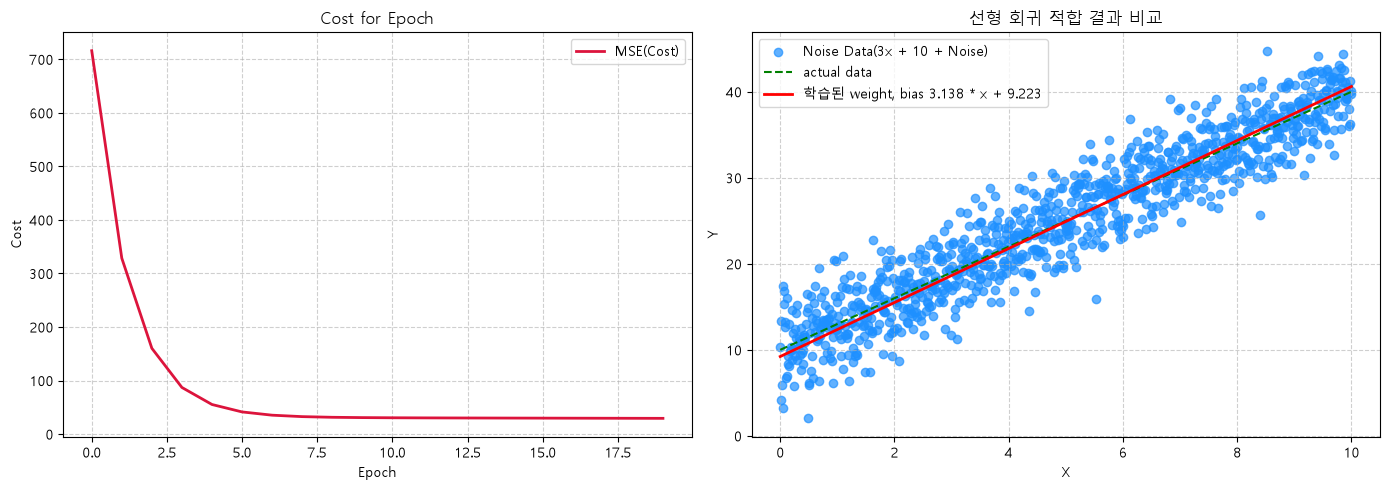

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = r'C:\Windows\Fonts\malgun.ttf'
font_name = fm.FontProperties(fname = font_path).get_name()

plt.rc('font', family = font_name)
plt.rcParams['axes.unicode_minus'] = False


np.random.seed(8)

x = np.linspace(0, 10, 1000).reshape(-1, 1)
# np.linspace(start, end, num_of_value)
noise = np.random.normal(loc = 0, scale = 3, size = x.shape)
# np.random.normal(loc = mean, scale = std, size = num_of_value)
y = 3 * x + 10 + noise

#weight
w = 0.0
w_history = []
#bias
b = 0.0
b_history = []

learning_rate = 0.01
epochs = 1000

cost_history = []
for epoch in range(epochs + 1):
    y_hat = w * x + b

    cost = np.mean((y_hat - y) ** 2)
    cost_history.append(cost)
    dw = np.mean((y_hat - y) * x)
    db = np.mean(y_hat - y)
    w_history.append(w)
    b_history.append(b)
    w = w - dw * learning_rate
    b = b - db * learning_rate

    if(epoch % 50) == 0:
        print(f"epoch : {epoch}, weight : {w:.3f}, bias : {b:.3f}, cost : {cost:.3f}")
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

axes[0].plot(cost_history[:20], color = 'crimson', linewidth = 2, label = "MSE(Cost)")
axes[0].set_title('Cost for Epoch', fontsize = 12)
axes[0].set_xlabel('Epoch', fontsize = 10)
axes[0].set_ylabel('Cost', fontsize = 10)
axes[0].grid(True, linestyle = '--', alpha = 0.6)
axes[0].legend()

axes[1].scatter(x, y, color = 'dodgerblue', alpha = 0.7, label = 'Noise Data(3x + 10 + Noise)')
axes[1].plot(x, 3*x + 10, color = 'green', linestyle = '--', linewidth = 1.5, label = 'actual data')
axes[1].plot(x, w * x + b, color = 'red', linewidth = 2, label = f'학습된 weight, bias {w:.3f} * x + {b:.3f}')
axes[1].set_title('선형 회귀 적합 결과 비교')
axes[1].set_xlabel('X', fontsize = 10)
axes[1].set_ylabel('Y', fontsize = 10)
axes[1].grid(True, linestyle = '--', alpha = 0.6)
axes[1].legend()

plt.tight_layout()
plt.show()